In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import (train_test_split,GridSearchCV,cross_val_score,StratifiedKFold)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_curve,roc_auc_score)

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


In [ ]:
df=pd.read_csv("dib.csv")

In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
print("Dataset shape:",df.shape)

Dataset shape: (768, 9)


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


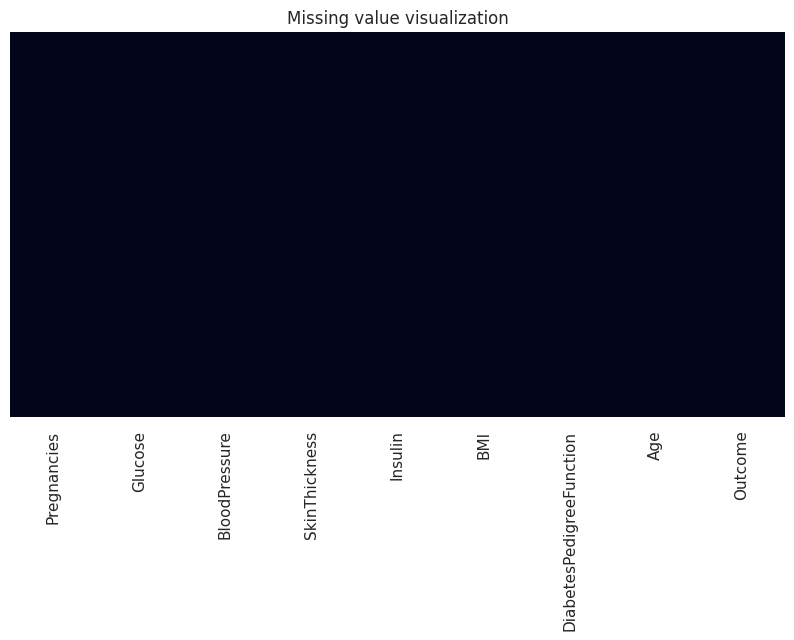

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(),cbar=False,yticklabels=False)
plt.title("Missing value visualization")
plt.show()

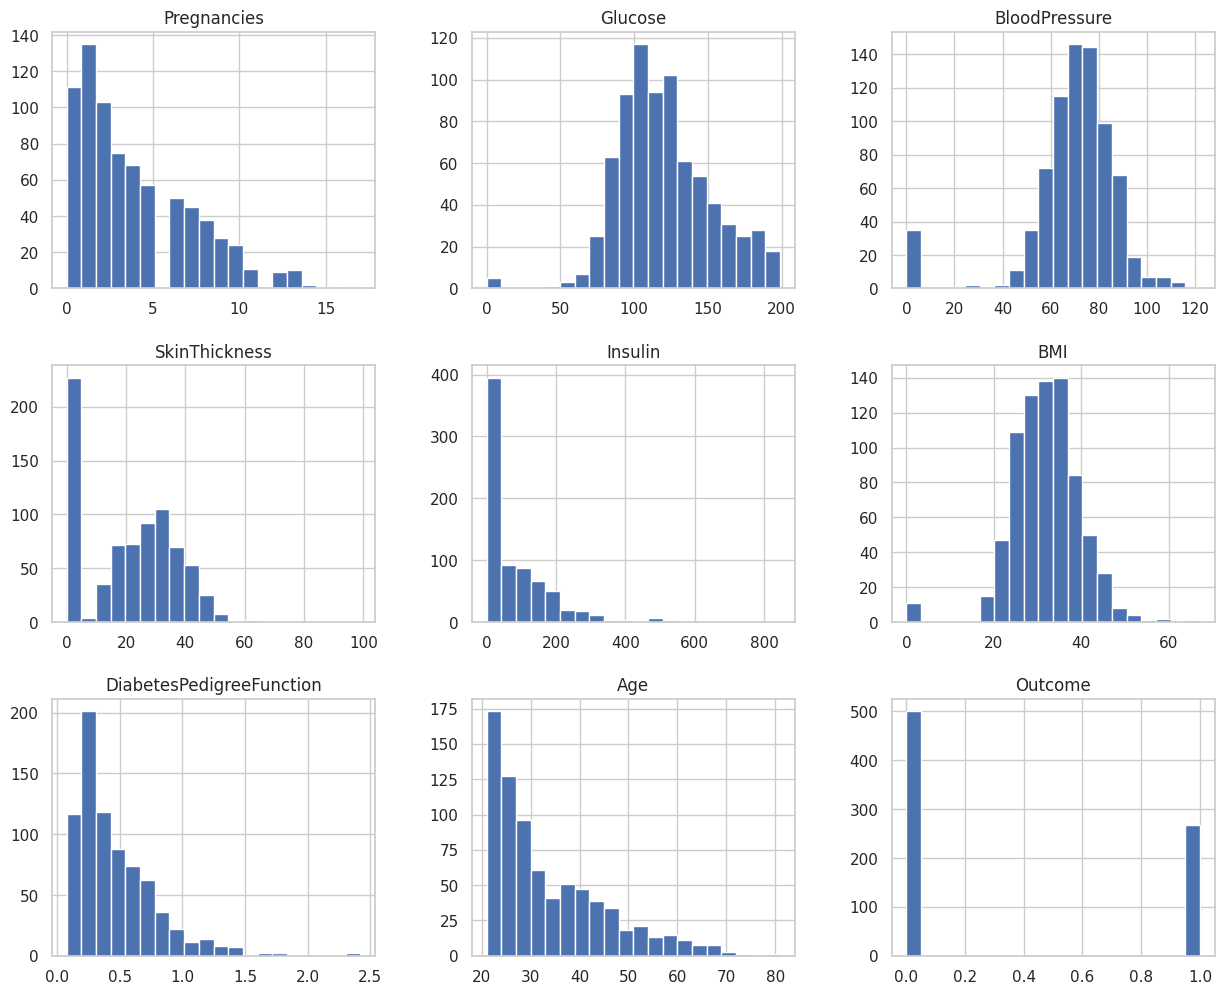

In [ ]:
df.hist(figsize=(15,12),bins=20)
plt.show()

In [ ]:
df.drop_duplicates().reset_index(drop=True)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
df.shape

(768, 9)

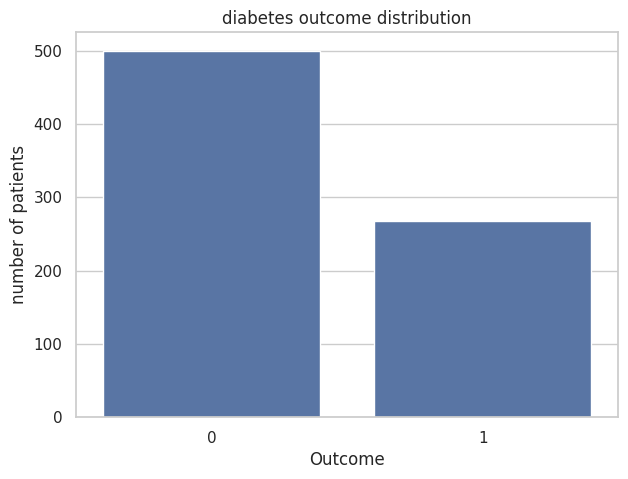

In [ ]:
plt.figure(figsize=(7,5))
sns.countplot(
    data=df,
    x="Outcome"
)
plt.title("diabetes outcome distribution")
plt.xlabel("Outcome")
plt.ylabel("number of patients")
plt.show()

In [ ]:
target_percentage=(
    df["Outcome"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    *100

)
print(target_percentage)


Outcome
0    6510.416667
1    3489.583333
Name: proportion, dtype: float64


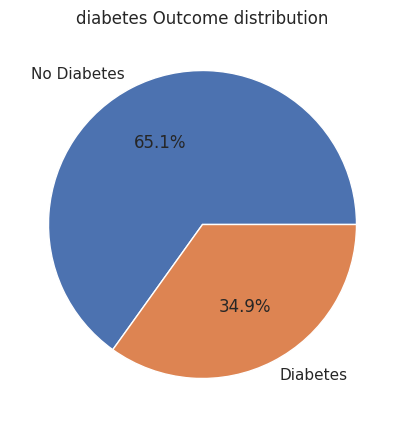

In [ ]:
plt.figure(figsize=(7,5))
plt.pie(target_percentage,labels=["No Diabetes","Diabetes"],autopct="%1.1f%%")
plt.title("diabetes Outcome distribution")
plt.show()

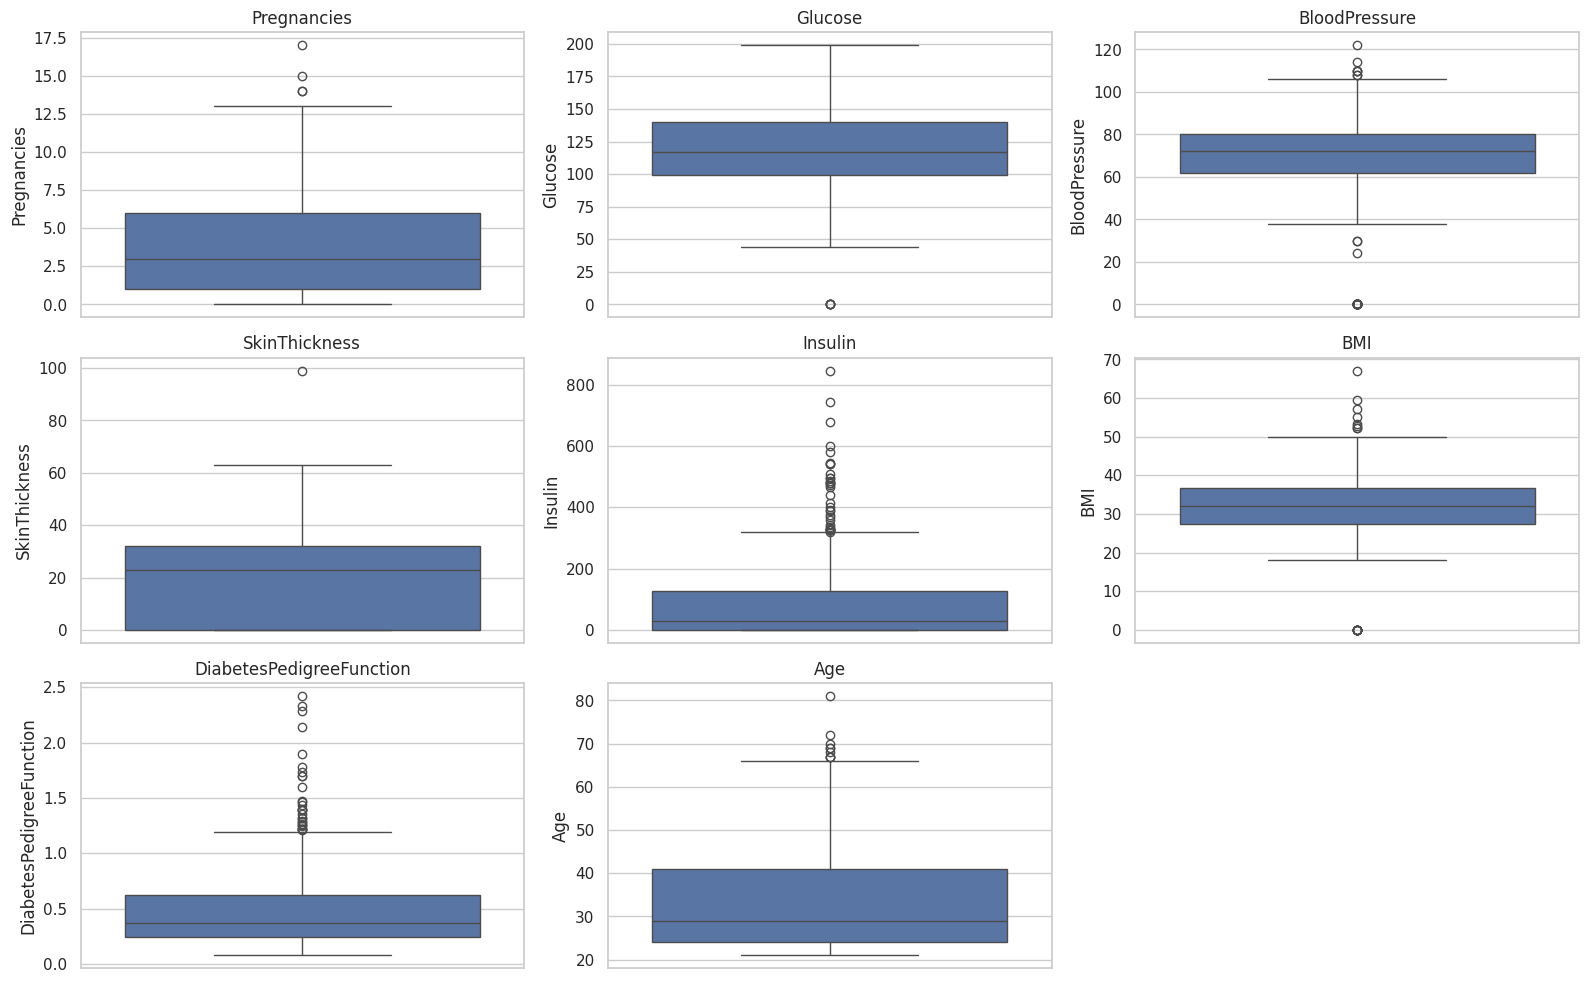

In [ ]:
features = df.drop('Outcome', axis=1).columns
plt.figure(figsize=(16,10))
for i ,col in enumerate(features,1):
  plt.subplot(3,3,i)
  sns.boxplot(y=df[col])
  plt.title(col)
plt.tight_layout()
plt.show()

In [ ]:
zero_columns=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
zero_counts=(df[zero_columns]==0).sum()
print(zero_counts)

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


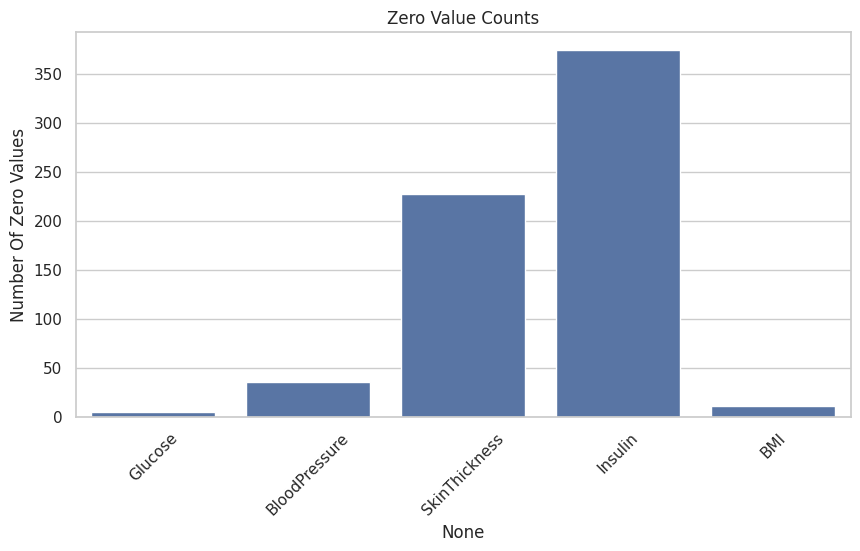

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(x=zero_counts.index,y=zero_counts.values)

plt.xticks(rotation=45)
plt.ylabel("Number Of Zero Values")
plt.title("Zero Value Counts")
plt.show()

In [ ]:
df_clean=df.copy()
df_clean[zero_columns]=df_clean[zero_columns].replace(0,np.nan)

print(df_clean.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


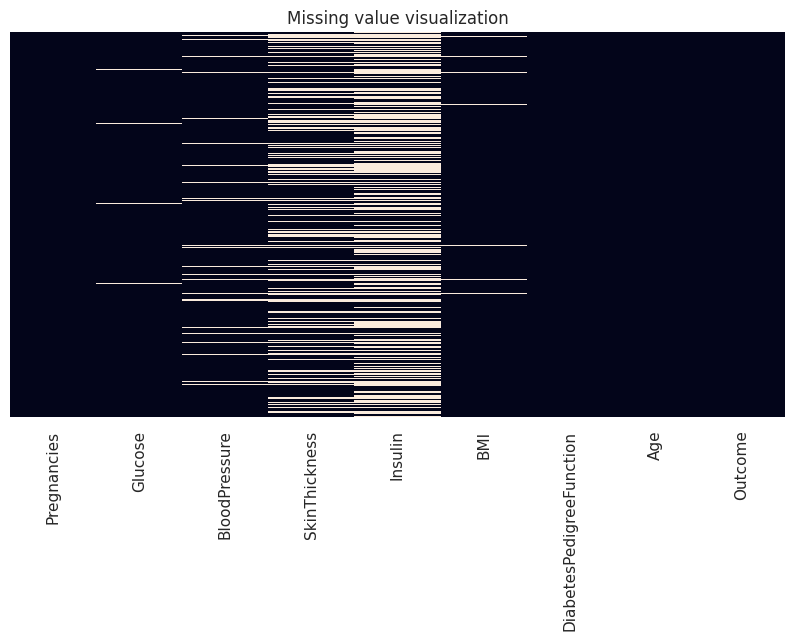

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df_clean.isnull(),cbar=False,yticklabels=False)
plt.title("Missing value visualization")
plt.show()

In [ ]:
for col in zero_columns:
  df_clean[col]=df_clean[col].fillna(df_clean[col].median())
  print(df_clean.isnull().sum())

Pregnancies                   0
Glucose                       0
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Pregnancies                   0
Glucose                       0
BloodPressure                 0
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Pregnancies                   0
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Pregnancies                  0
Glucose                      0
BloodPressure                0
Skin

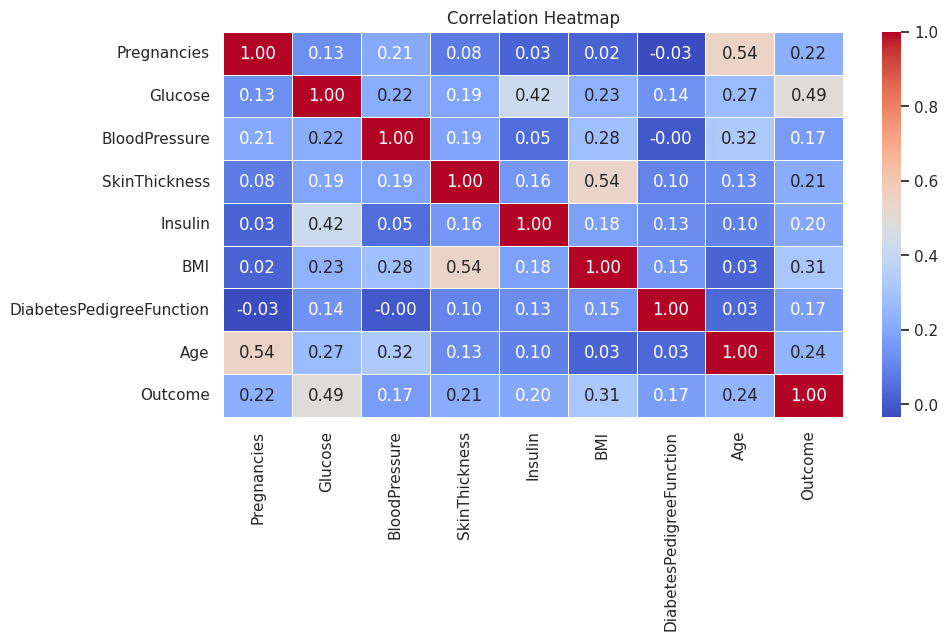

In [ ]:
correlation = df_clean.corr()
plt.figure(figsize=(10,5))
sns.heatmap(correlation,annot=True,fmt=".2f",cmap="coolwarm",linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
target_corr=(df_clean.corr()["Outcome"].drop("Outcome")).sort_values(ascending=False)
print(target_corr)

Glucose                     0.492782
BMI                         0.312038
Age                         0.238356
Pregnancies                 0.221898
SkinThickness               0.214873
Insulin                     0.203790
DiabetesPedigreeFunction    0.173844
BloodPressure               0.165723
Name: Outcome, dtype: float64


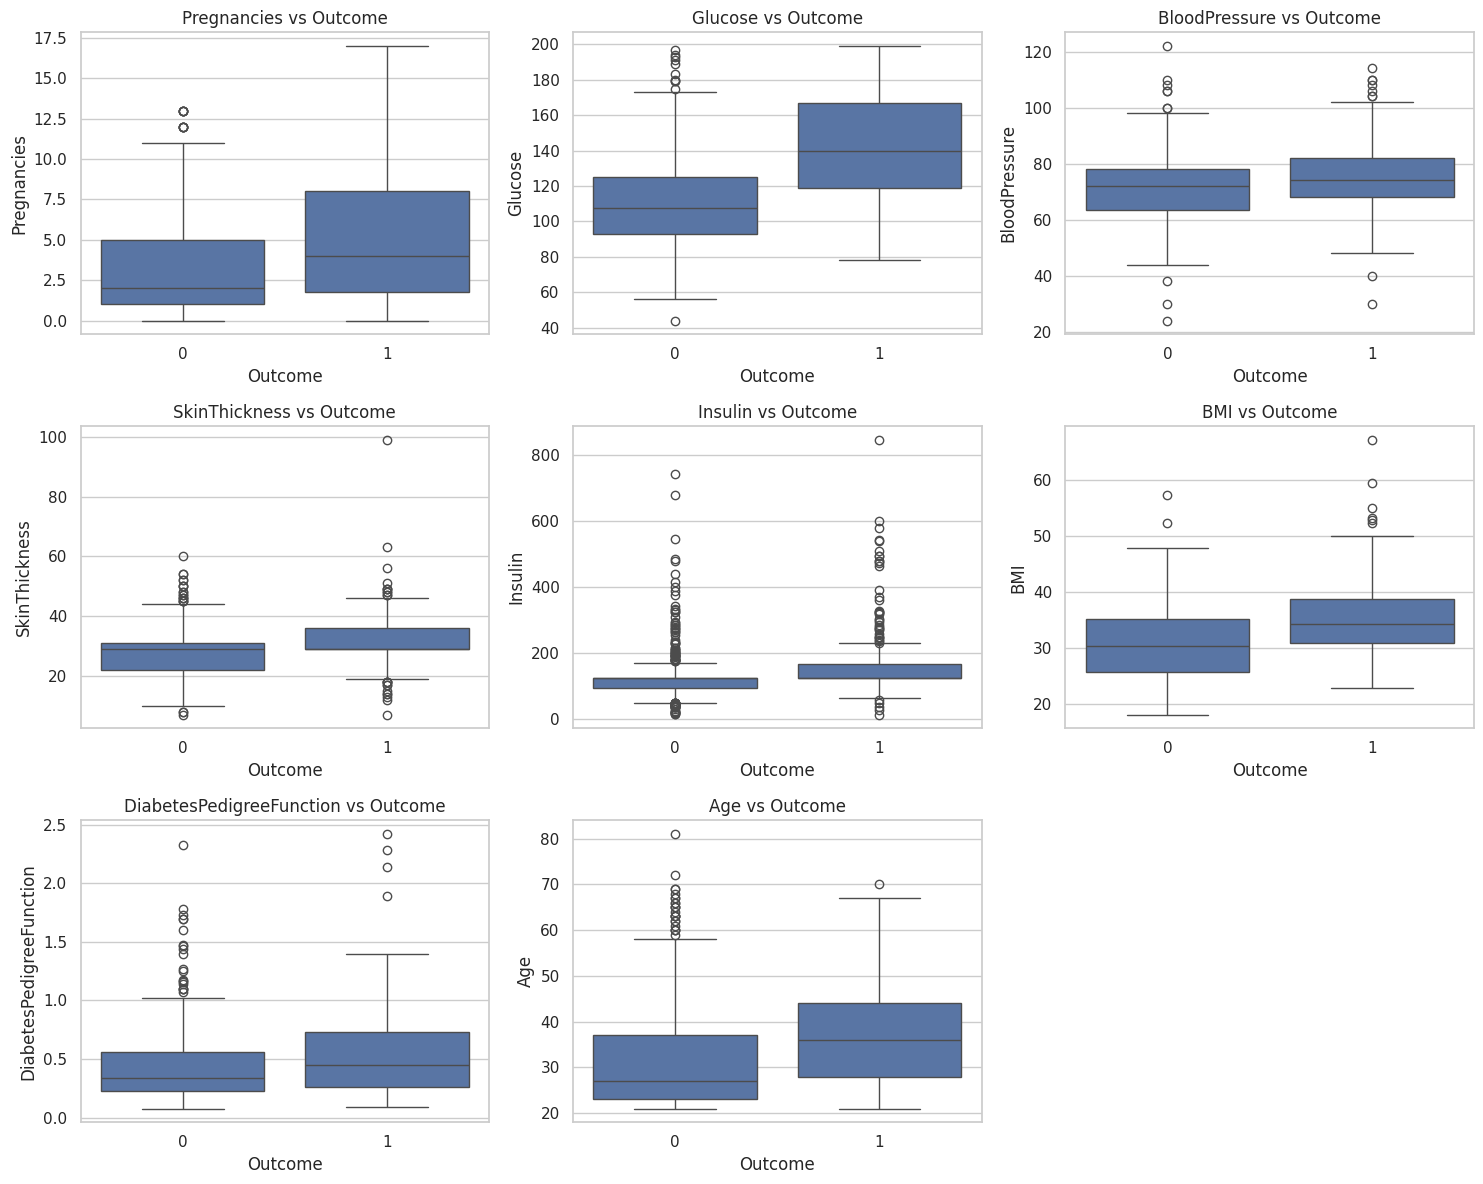

In [ ]:
plt.figure(figsize=(15,12))
for i , col in enumerate(features,1):
  plt.subplot(3,3,i)
  sns.boxplot(data=df_clean,x="Outcome",y=col)
  plt.title(f"{col} vs Outcome")
plt.tight_layout()
plt.show()

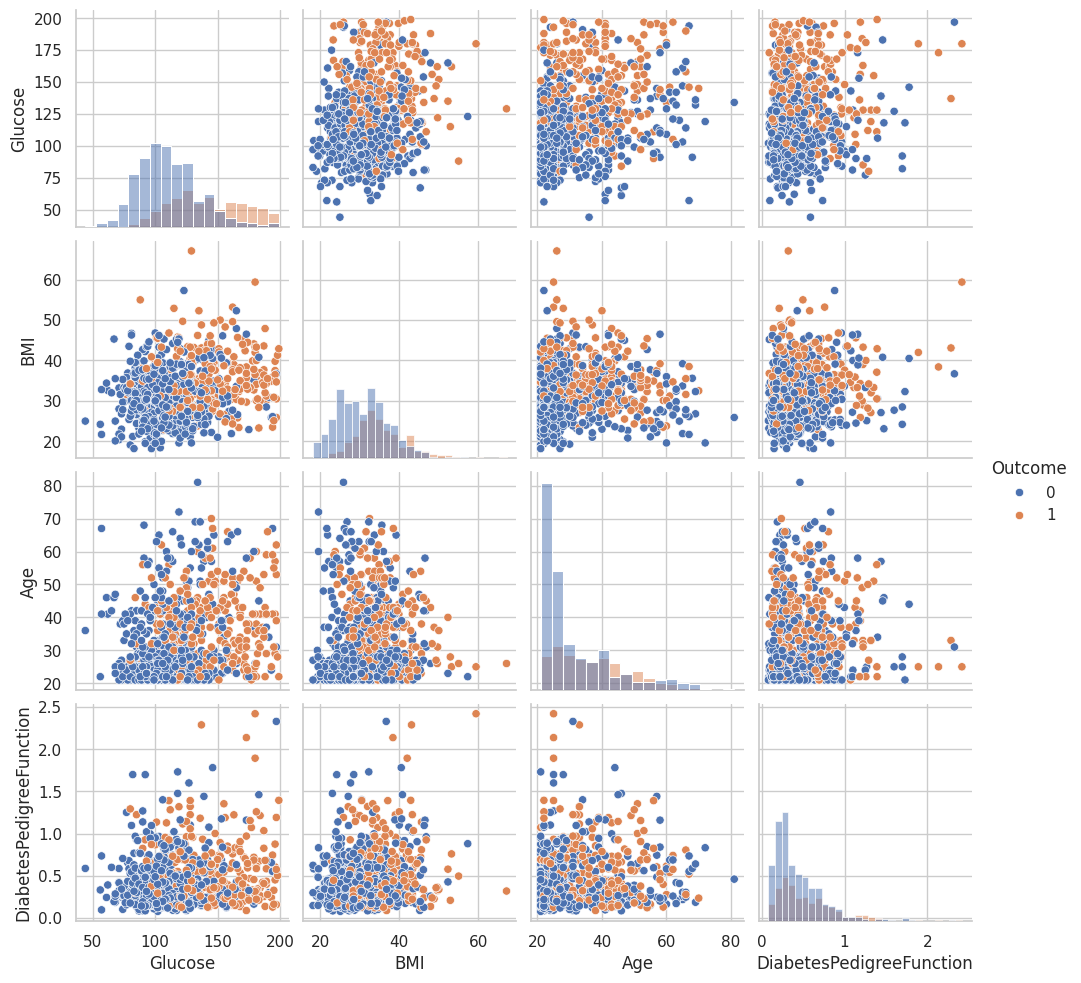

In [ ]:
selected_features=["Glucose","BMI","Age","DiabetesPedigreeFunction","Outcome"]
sns.pairplot(df_clean[selected_features],hue="Outcome",diag_kind="hist")
plt.show()


In [ ]:
X=df_clean.drop("Outcome",axis=1)
y=df_clean["Outcome"]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print(X_train.shape[0])
print(X_test.shape[0])

614
154


In [ ]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [ ]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [ ]:
scaler.fit_transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [ ]:
scaler.transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [ ]:
comparison=pd.DataFrame({
    "Original Mean":X_train.mean(),
    "Original Std":X_train.std(),
    "Scaled Mean":X_train_scaled.mean(),
    "Scaled Std":X_train_scaled.std()
})
print(comparison)


                          Original Mean  Original Std   Scaled Mean  Scaled Std
Pregnancies                    3.819218      3.314148 -1.566789e-16         1.0
Glucose                      121.671010     30.003794 -1.566789e-16         1.0
BloodPressure                 72.140065     12.275119 -1.566789e-16         1.0
SkinThickness                 29.042345      8.891855 -1.566789e-16         1.0
Insulin                      137.705212     78.764767 -1.566789e-16         1.0
BMI                           32.446743      6.824142 -1.566789e-16         1.0
DiabetesPedigreeFunction       0.477428      0.330300 -1.566789e-16         1.0
Age                           33.366450     11.833438 -1.566789e-16         1.0


In [ ]:
model = KNeighborsClassifier(n_neighbors=5)

In [ ]:
model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [ ]:
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

In [ ]:
print(f'{accuracy:.4f}')

0.7532


In [ ]:
f1 = f1_score(y_test, y_pred)
print(f"{f1:.4f}")

0.6346
